In [5]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             r2_score, mean_absolute_error, mean_squared_error, f1_score)
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
NIM = '202431164'
os.makedirs('fig', exist_ok=True)
RES = {}

def wm(fig):
    # watermark NIM pada setiap gambar
    fig.text(0.5, 0.5, NIM, fontsize=48, color='gray', alpha=0.15,
             ha='center', va='center', rotation=30)

def save(fig, name):
    wm(fig); fig.tight_layout(); fig.savefig(f'fig/{name}.png', dpi=130); plt.show()
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')


[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [6]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
from pathlib import Path
FILE = '04_bank_customers.csv'

def find_csv(name):
    # cari file di folder kerja, folder induk, lalu Downloads/Desktop/Documents, lalu subfolder
    home = Path.home()
    for p in [Path.cwd()/name, Path.cwd().parent/name, home/'Downloads'/name,
              home/'Desktop'/name, home/'Documents'/name]:
        if p.exists(): return p
    for p in Path.cwd().rglob(name): return p
    return None

path = find_csv(FILE)
if path is None:   # jika tidak ketemu, minta pilih file lewat jendela dialog
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk(); root.withdraw(); root.attributes('-topmost', True)
        sel = filedialog.askopenfilename(title='Pilih 04_bank_customers.csv', filetypes=[('CSV','*.csv')])
        root.destroy()
        path = Path(sel) if sel else None
    except Exception:
        path = None
if path is None:
    raise FileNotFoundError(f'{FILE} tidak ditemukan. Letakkan file di folder: {Path.cwd()}')

print('Dataset dibaca dari:', path)
df = pd.read_csv(path, sep=';')
print('Ukuran data (baris, kolom):', df.shape)
df.head()
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

Dataset dibaca dari: C:\Users\ACER\Downloads\Dataset_UTS_2026\Dataset_UTS_2026\04_bank_customers.csv
Ukuran data (baris, kolom): (45211, 17)

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [7]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
df.info()
print('\nMissing value per kolom:\n', df.isna().sum())
print('\nJumlah duplikat:', df.duplicated().sum())
print('\nNilai "unknown" per kolom kategorikal:')
print((df.select_dtypes('object') == 'unknown').sum()[lambda s: s > 0])
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Missing value per kolom:
 age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
l

In [8]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
df.describe().T
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')


[Watermark] NIM 202431164 - Fajar Febriano Admosa


y
no     39922
yes     5289
Name: count, dtype: int64 
 y
no     88.3
yes    11.7
Name: count, dtype: float64


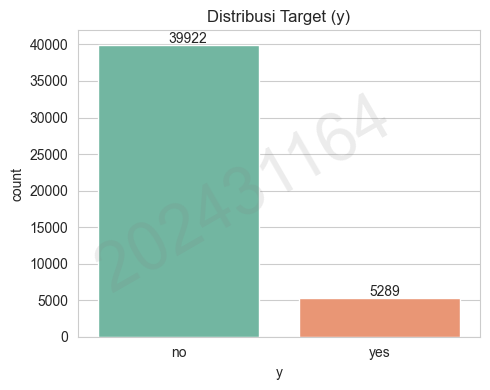


[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [9]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
vc = df['y'].value_counts()
print(vc, '\n', (vc/len(df)*100).round(2))
RES['target_counts'] = vc.to_dict()s
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(x='y', data=df, ax=ax, palette='Set2')
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+.35, p.get_height()+300))
ax.set_title('Distribusi Target (y)')
save(fig, 'eda_target')
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

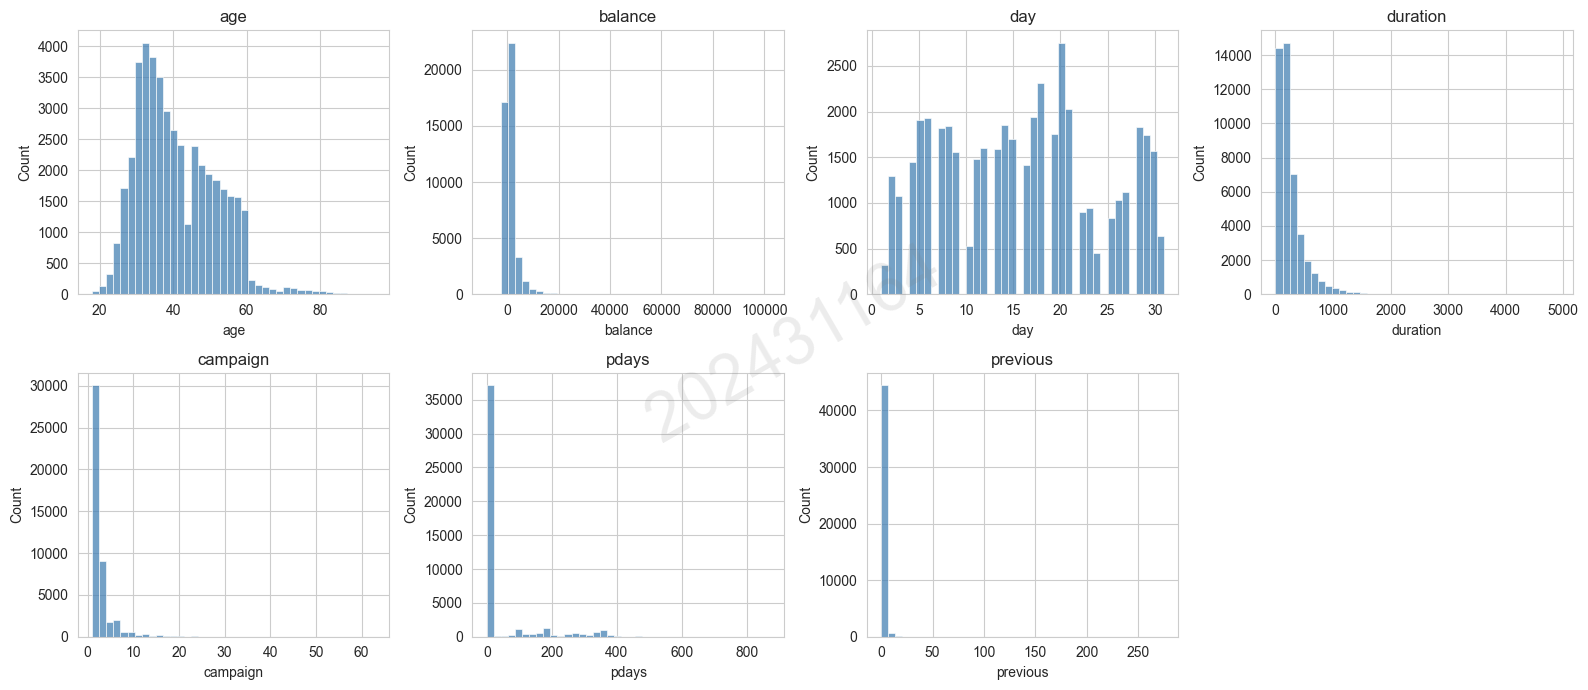


[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [10]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
num_cols = df.select_dtypes(include='number').columns.tolist()
fig, axes = plt.subplots(2, 4, figsize=(16,7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=40, kde=False, ax=ax, color='steelblue'); ax.set_title(c)
axes.ravel()[-1].axis('off')
save(fig, 'eda_numeric')
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

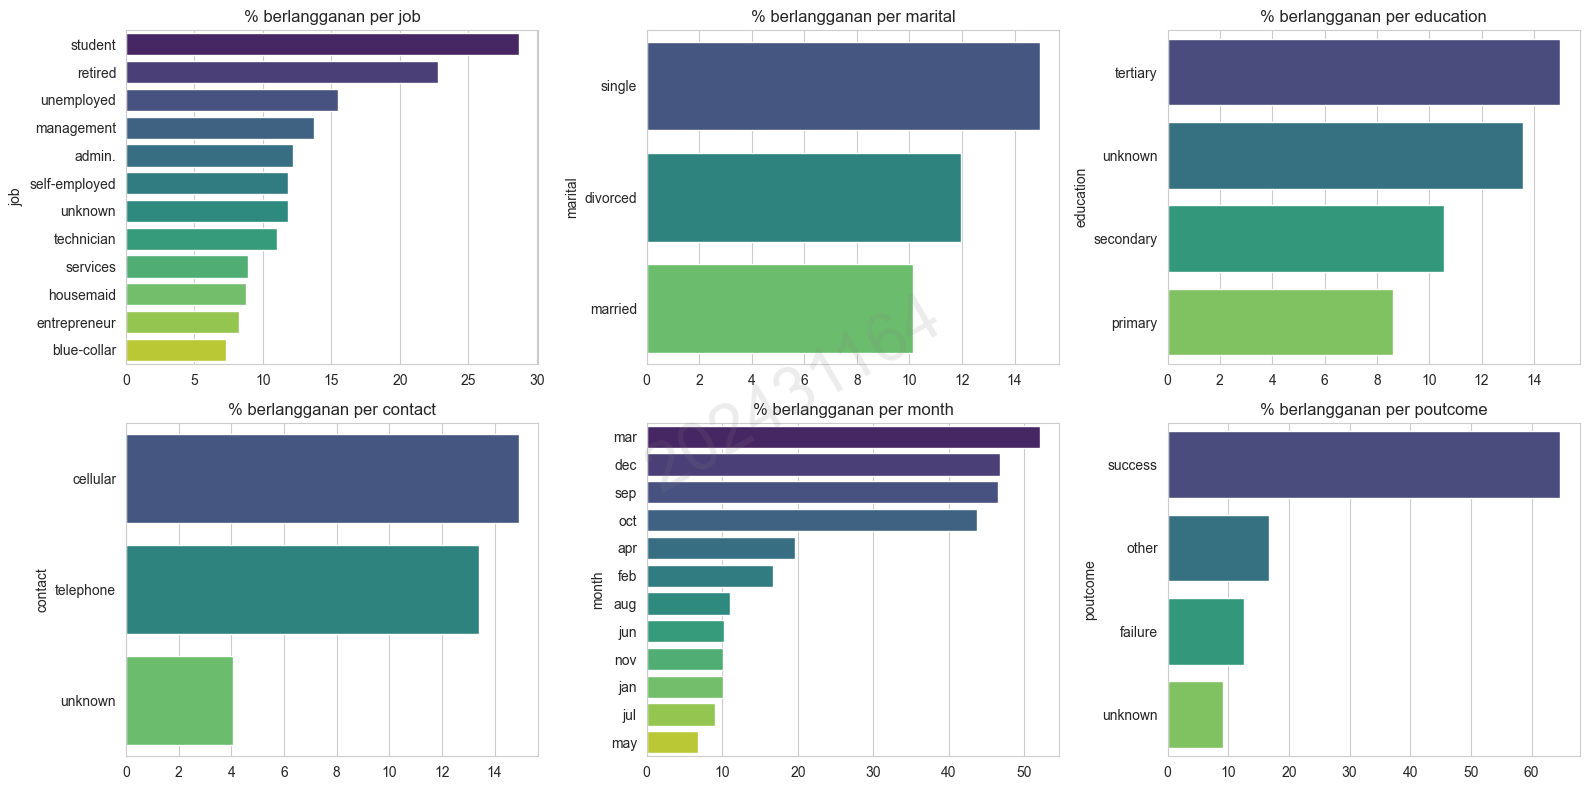


[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [11]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
cat_cols = df.select_dtypes('object').columns.drop('y').tolist()
tmp = df.assign(y_bin=(df['y']=='yes').astype(int))
fig, axes = plt.subplots(2, 3, figsize=(16,8))
for ax, c in zip(axes.ravel(), ['job','marital','education','contact','month','poutcome']):
    r = tmp.groupby(c)['y_bin'].mean().sort_values(ascending=False)*100
    sns.barplot(x=r.values, y=r.index, ax=ax, palette='viridis'); ax.set_title(f'% berlangganan per {c}')
save(fig, 'eda_categorical')
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

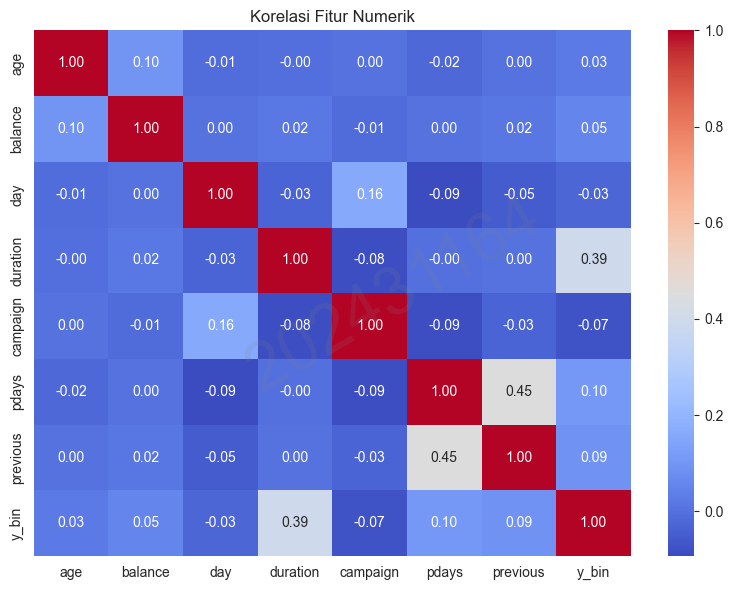

y_bin       1.000000
duration    0.394521
pdays       0.103621
previous    0.093236
balance     0.052838
age         0.025155
day        -0.028348
campaign   -0.073172
Name: y_bin, dtype: float64

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [12]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
corr = tmp[num_cols + ['y_bin']].corr()
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax); ax.set_title('Korelasi Fitur Numerik')
save(fig, 'eda_corr')
print(corr['y_bin'].sort_values(ascending=False))
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

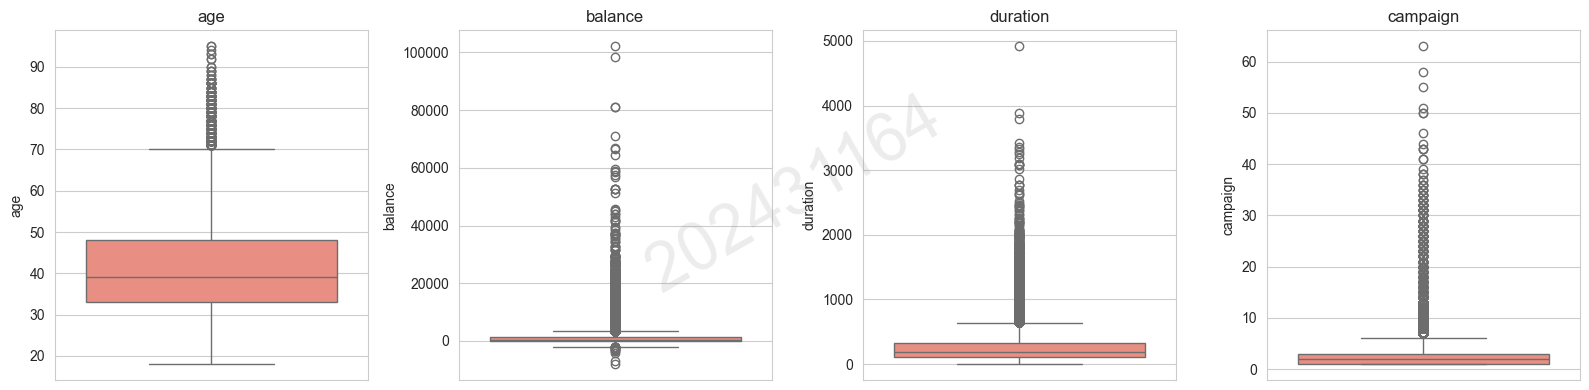

age        outlier IQR: 487 (1.1%)
balance    outlier IQR: 4729 (10.5%)
duration   outlier IQR: 3235 (7.2%)
campaign   outlier IQR: 3064 (6.8%)

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [13]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, c in zip(axes, ['age','balance','duration','campaign']):
    sns.boxplot(y=df[c], ax=ax, color='salmon'); ax.set_title(c)
save(fig, 'eda_outlier')
for c in ['age','balance','duration','campaign']:
    q1,q3 = df[c].quantile([.25,.75]); i = q3-q1
    n = ((df[c] < q1-1.5*i) | (df[c] > q3+1.5*i)).sum()
    print(f'{c:10s} outlier IQR: {n} ({n/len(df)*100:.1f}%)')
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

In [14]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
data = df.drop_duplicates().copy()
data['y'] = data['y'].map({'no':0, 'yes':1})
X = pd.get_dummies(data.drop(columns='y'), drop_first=True, dtype=int)
y = data['y']
print('Bentuk X setelah encoding:', X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi y=1 train/test:', round(y_train.mean(),4), round(y_test.mean(),4))

sc = StandardScaler().fit(X_train[num_cols])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = sc.transform(X_train[num_cols])
X_test_s[num_cols]  = sc.transform(X_test[num_cols])
RES['n_features'] = X.shape[1]; RES['n_train'] = len(X_train); RES['n_test'] = len(X_test)
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

Bentuk X setelah encoding: (45211, 42)
Train: (36168, 42) | Test: (9043, 42)
Proporsi y=1 train/test: 0.117 0.117

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [15]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
lr = LinearRegression().fit(X_train_s, y_train)
pred_cont = lr.predict(X_test_s)
pred_lr = (pred_cont >= 0.5).astype(int)

acc_lr = accuracy_score(y_test, pred_lr)
RES['lr'] = dict(accuracy=acc_lr, f1=f1_score(y_test, pred_lr), r2=r2_score(y_test, pred_cont),
                 mae=mean_absolute_error(y_test, pred_cont), mse=mean_squared_error(y_test, pred_cont),
                 rmse=float(np.sqrt(mean_squared_error(y_test, pred_cont))),
                 train_acc=accuracy_score(y_train, (lr.predict(X_train_s)>=0.5).astype(int)))
print({k: round(v,4) for k,v in RES['lr'].items()})
print('\nClassification report:\n', classification_report(y_test, pred_lr))
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

{'accuracy': 0.8984, 'f1': 0.3902, 'r2': 0.2978, 'mae': 0.1615, 'mse': 0.0725, 'rmse': 0.2693, 'train_acc': 0.8998}

Classification report:
               precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.65      0.28      0.39      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.63      0.67      9043
weighted avg       0.88      0.90      0.88      9043


[Watermark] NIM 202431164 - Fajar Febriano Admosa


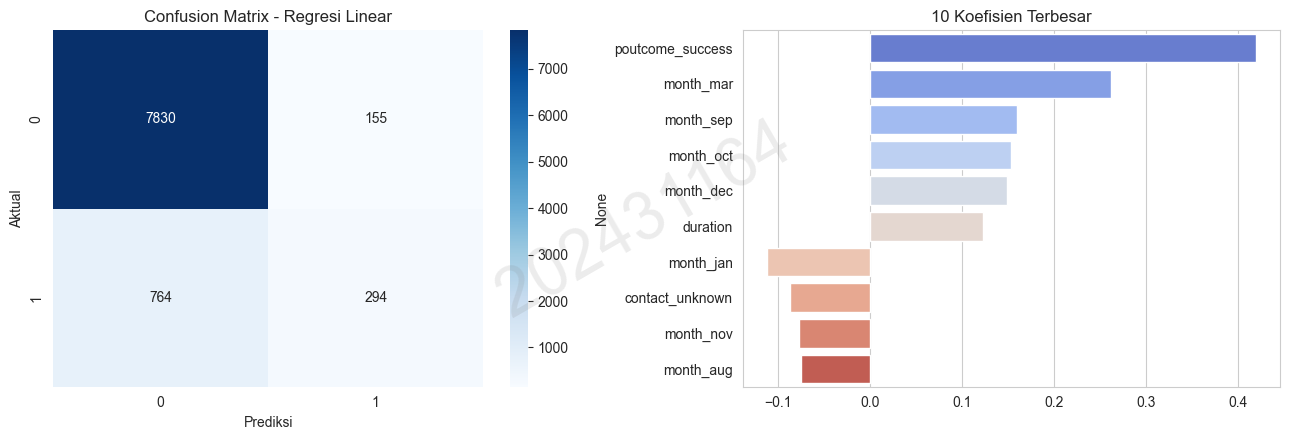

poutcome_success    0.419527
month_mar           0.262161
month_sep           0.159260
month_oct           0.153448
month_dec           0.148903
duration            0.122514
month_jan          -0.112363
contact_unknown    -0.087313
month_nov          -0.077500
month_aug          -0.075220
dtype: float64

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [16]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
cm = confusion_matrix(y_test, pred_lr); RES['lr']['cm'] = cm.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0]); axes[0].set_title('Confusion Matrix - Regresi Linear')
axes[0].set_xlabel('Prediksi'); axes[0].set_ylabel('Aktual')
coef = pd.Series(lr.coef_, index=X.columns).sort_values(key=abs, ascending=False).head(10)
sns.barplot(x=coef.values, y=coef.index, ax=axes[1], palette='coolwarm'); axes[1].set_title('10 Koefisien Terbesar')
save(fig, 'lr_result')
RES['lr']['top_coef'] = coef.round(4).to_dict()
print(coef)
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

In [17]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
dt0 = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
RES['dt_base'] = dict(train_acc=dt0.score(X_train, y_train), accuracy=dt0.score(X_test, y_test),
                      f1=f1_score(y_test, dt0.predict(X_test)), depth=int(dt0.get_depth()))
print('Decision Tree tanpa batasan:', {k: round(v,4) for k,v in RES['dt_base'].items()})
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

Decision Tree tanpa batasan: {'train_acc': 1.0, 'accuracy': 0.8776, 'f1': 0.4882, 'depth': 35}

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [19]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
    {'max_depth':[3,5,7,10,15], 'min_samples_leaf':[1,10,30,50], 'criterion':['gini','entropy']},
    cv=5, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
dt = grid.best_estimator_
pred_dt = dt.predict(X_test)
print('Parameter terbaik:', grid.best_params_, '| CV acc:', round(grid.best_score_,4))
RES['dt'] = dict(accuracy=accuracy_score(y_test, pred_dt), f1=f1_score(y_test, pred_dt),
                 train_acc=dt.score(X_train, y_train), cv_acc=grid.best_score_,
                 params=grid.best_params_, depth=int(dt.get_depth()))
print({k: (round(v,4) if isinstance(v,float) else v) for k,v in RES['dt'].items()})
print('\nClassification report:\n', classification_report(y_test, pred_dt))
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

Parameter terbaik: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 30} | CV acc: 0.9033
{'accuracy': 0.899, 'f1': 0.4218, 'train_acc': 0.9045, 'cv_acc': np.float64(0.9033), 'params': {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 30}, 'depth': 5}

Classification report:
               precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.64      0.31      0.42      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.65      0.68      9043
weighted avg       0.88      0.90      0.88      9043


[Watermark] NIM 202431164 - Fajar Febriano Admosa


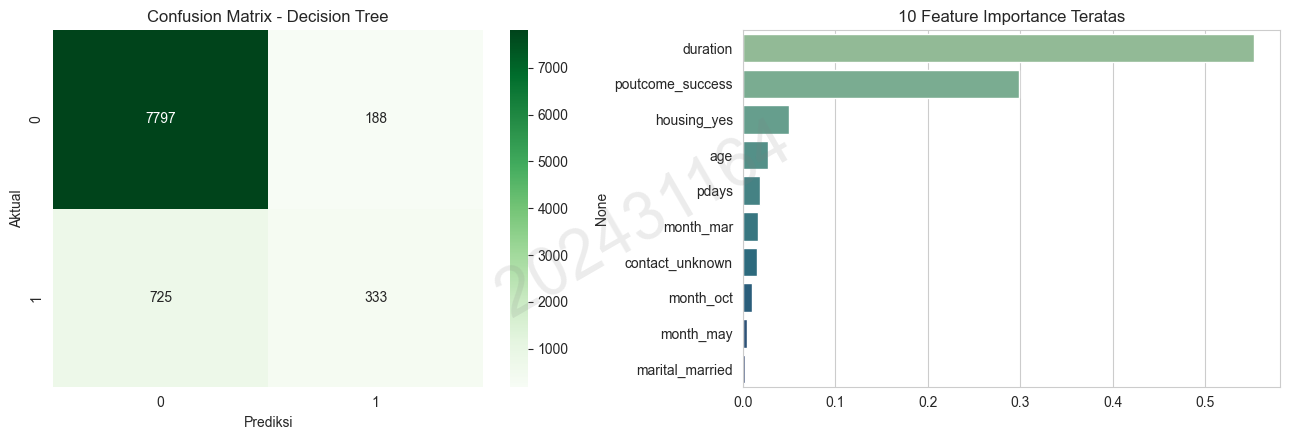

duration            0.553283
poutcome_success    0.298430
housing_yes         0.050157
age                 0.026984
pdays               0.018788
month_mar           0.016774
contact_unknown     0.015656
month_oct           0.010212
month_may           0.005044
marital_married     0.002169
dtype: float64

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [20]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
cm2 = confusion_matrix(y_test, pred_dt); RES['dt']['cm'] = cm2.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens', ax=axes[0]); axes[0].set_title('Confusion Matrix - Decision Tree')
axes[0].set_xlabel('Prediksi'); axes[0].set_ylabel('Aktual')
imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
sns.barplot(x=imp.values, y=imp.index, ax=axes[1], palette='crest'); axes[1].set_title('10 Feature Importance Teratas')
save(fig, 'dt_result')
RES['dt']['top_imp'] = imp.round(4).to_dict()
print(imp)
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

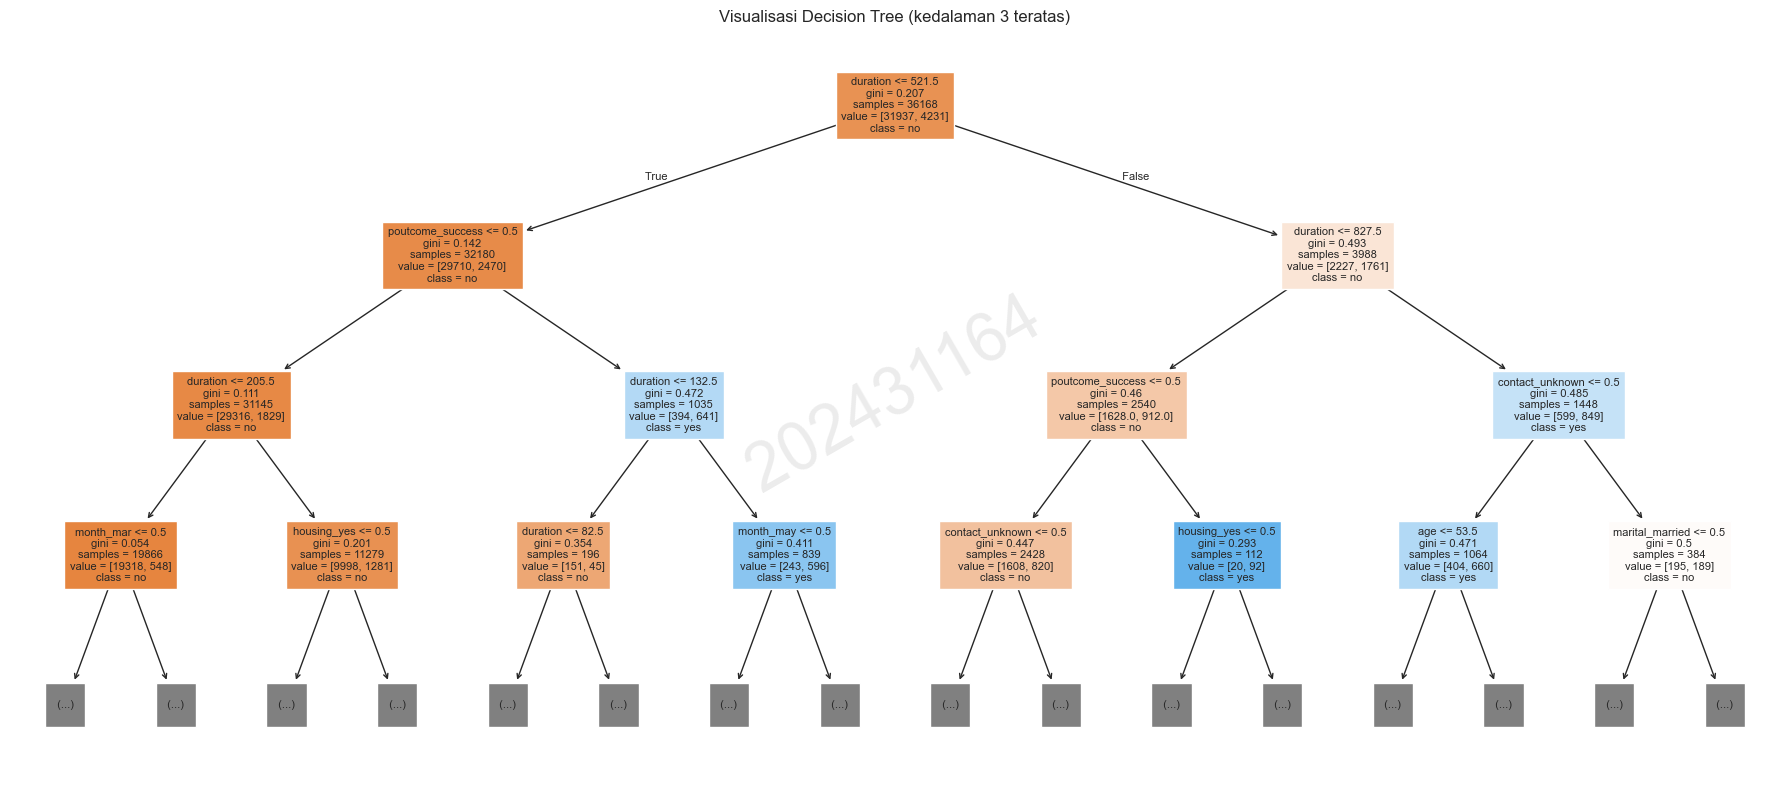


[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [21]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
fig = plt.figure(figsize=(18,8))
plot_tree(dt, max_depth=3, feature_names=X.columns, class_names=['no','yes'], filled=True, fontsize=8)
plt.title('Visualisasi Decision Tree (kedalaman 3 teratas)')
save(fig, 'dt_tree')
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')

                         Model  Akurasi Test  F1 (kelas yes)
Regresi Linear (threshold 0.5)        0.8984          0.3902
      Decision Tree (baseline)        0.8776          0.4882
         Decision Tree (tuned)        0.8990          0.4218


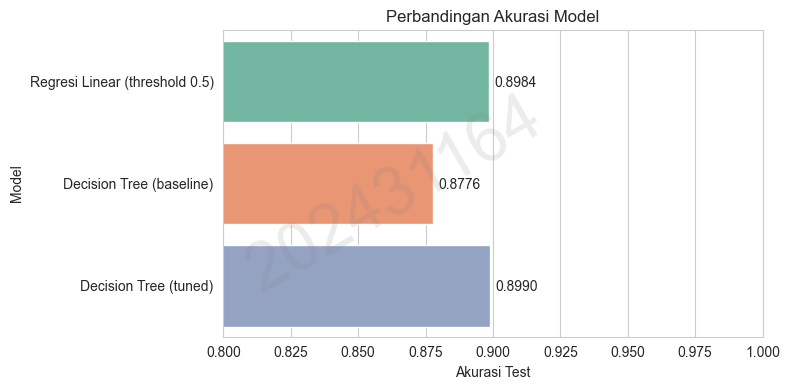


Model terbaik: Decision Tree (tuned) | akurasi = 0.899

[Watermark] NIM 202431164 - Fajar Febriano Admosa


In [22]:
# ===== NIM 202431164 | Fajar Febriano Admosa =====
comp = pd.DataFrame({
  'Model': ['Regresi Linear (threshold 0.5)', 'Decision Tree (baseline)', 'Decision Tree (tuned)'],
  'Akurasi Test': [RES['lr']['accuracy'], RES['dt_base']['accuracy'], RES['dt']['accuracy']],
  'F1 (kelas yes)': [RES['lr']['f1'], RES['dt_base']['f1'], RES['dt']['f1']],
}).round(4)
print(comp.to_string(index=False))
fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(data=comp, x='Akurasi Test', y='Model', ax=ax, palette='Set2'); ax.set_xlim(0.8, 1.0)
for p in ax.patches: ax.annotate(f'{p.get_width():.4f}', (p.get_width()+.002, p.get_y()+.45))
ax.set_title('Perbandingan Akurasi Model')
save(fig, 'comparison')
best = comp.sort_values('Akurasi Test').iloc[-1]
print('\nModel terbaik:', best['Model'], '| akurasi =', best['Akurasi Test'])
json.dump(RES, open('results.json','w'), indent=2, default=float)
print('\n[Watermark] NIM 202431164 - Fajar Febriano Admosa')